In [5]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import time
from collections import defaultdict
from kafka import KafkaConsumer

KAFKA_BROKER = 'localhost:6502'
TOPIC_REQUESTS = 'REQUESTS_PER_DAY'
TOPIC_STATS = 'STATUS_STATS'

def collect_requests_per_day(timeout_sec=10):
    consumer = KafkaConsumer(
        TOPIC_REQUESTS,
        bootstrap_servers=KAFKA_BROKER,
        auto_offset_reset='earliest',
        enable_auto_commit=False,
        consumer_timeout_ms=1000,
        value_deserializer=lambda m: json.loads(m.decode('utf-8'))
    )
    
    agg = defaultdict(int)
    start = time.time()
    
    for msg in consumer:
        if time.time() - start > timeout_sec:
            break
        
        val = msg.value
        day = val.get('DAY')
        requests = val.get('REQUESTS')
        if day is None or requests is None:
            continue
            
        url = msg.key.split(b'\x00')[0].decode('utf-8')
        key = (url, day)
        if requests > agg[key]:
            agg[key] = requests
    
    consumer.close()
    
    records = [
        {'url': url, 'day': pd.to_datetime(day, unit='ms'), 'requests': cnt}
        for (url, day), cnt in agg.items()
    ]
    print(records)
    
    return pd.DataFrame(records)

def collect_status_stats(timeout_sec=10):
    consumer = KafkaConsumer(
        TOPIC_STATS,
        bootstrap_servers=KAFKA_BROKER,
        auto_offset_reset='earliest',
        enable_auto_commit=False,
        consumer_timeout_ms=1000,
        value_deserializer=lambda m: json.loads(m.decode('utf-8'))
    )
    
    agg = {}
    start = time.time()
    
    for msg in consumer:
        if time.time() - start > timeout_sec:
            break
        
        val = msg.value
        total = val.get('TOTAL')
        if total is None:
            continue
        url = msg.key.split(b'\x00')[0].decode('utf-8')
        agg[url] = (total, val.get('SUCCESS', 0), val.get('FAILED', 0))
    
    consumer.close()
    
    records = [
        {'url': url, 'total': t, 'success': s, 'failed': f}
        for url, (t, s, f) in agg.items()
    ]
    print(records)
    return pd.DataFrame(records)

In [6]:
def plot_requests_per_day(df_requests):
    df_requests = df_requests.sort_values(['url', 'day'])
    
    urls = df_requests['url'].unique()
    fig, axes = plt.subplots(nrows=len(urls), figsize=(12, 3*len(urls)), sharex=True)
    if len(urls) == 1:
        axes = [axes]
    
    for ax, url in zip(axes, urls):
        sub = df_requests[df_requests['url'] == url]
        ax.plot(sub['day'], sub['requests'], marker='o', linestyle='-')
        ax.set_title(f'Requests per day: {url}')
        ax.set_ylabel('Requests')
        ax.grid(True)
    plt.xlabel('Date')
    plt.tight_layout()
    plt.savefig('requests_per_day.png')
    plt.show()

def plot_success_fail_rates(df_stats):
    df_stats['success_rate'] = df_stats['success'] / df_stats['total']
    df_stats['fail_rate'] = df_stats['failed'] / df_stats['total']
    
    df_stats = df_stats.sort_values('success_rate', ascending=False)
    
    x = range(len(df_stats))
    width = 0.35
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x, df_stats['success_rate'], width, label='Success rate', color='green')
    ax.bar(x, df_stats['fail_rate'], width, label='Fail rate', bottom=df_stats['success_rate'], color='red')
    ax.set_ylabel('Rate')
    ax.set_title('Success vs Fail rates for top-10 URLs')
    ax.set_xticks(x)
    ax.set_xticklabels(df_stats['url'], rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y')
    plt.tight_layout()
    plt.savefig('success_fail_rates.png')
    plt.show()

[{'url': '/images/ksclogo-medium.gif', 'day': Timestamp('1995-08-01 00:00:00'), 'requests': 4174}, {'url': '/images/MOSAIC-logosmall.gif', 'day': Timestamp('1995-08-01 00:00:00'), 'requests': 4289}, {'url': '/history/apollo/images/apollo-logo1.gif', 'day': Timestamp('1995-08-01 00:00:00'), 'requests': 1584}, {'url': '/images/KSC-logosmall.gif', 'day': Timestamp('1995-08-01 00:00:00'), 'requests': 3437}, {'url': '/images/ksclogo-medium.gif', 'day': Timestamp('1995-08-03 00:00:00'), 'requests': 3546}, {'url': '/images/KSC-logosmall.gif', 'day': Timestamp('1995-08-03 00:00:00'), 'requests': 3806}, {'url': '/images/MOSAIC-logosmall.gif', 'day': Timestamp('1995-08-03 00:00:00'), 'requests': 3648}, {'url': '/history/apollo/images/apollo-logo1.gif', 'day': Timestamp('1995-08-03 00:00:00'), 'requests': 1734}, {'url': '/images/KSC-logosmall.gif', 'day': Timestamp('1995-08-04 00:00:00'), 'requests': 5082}, {'url': '/history/apollo/images/apollo-logo1.gif', 'day': Timestamp('1995-08-04 00:00:00')

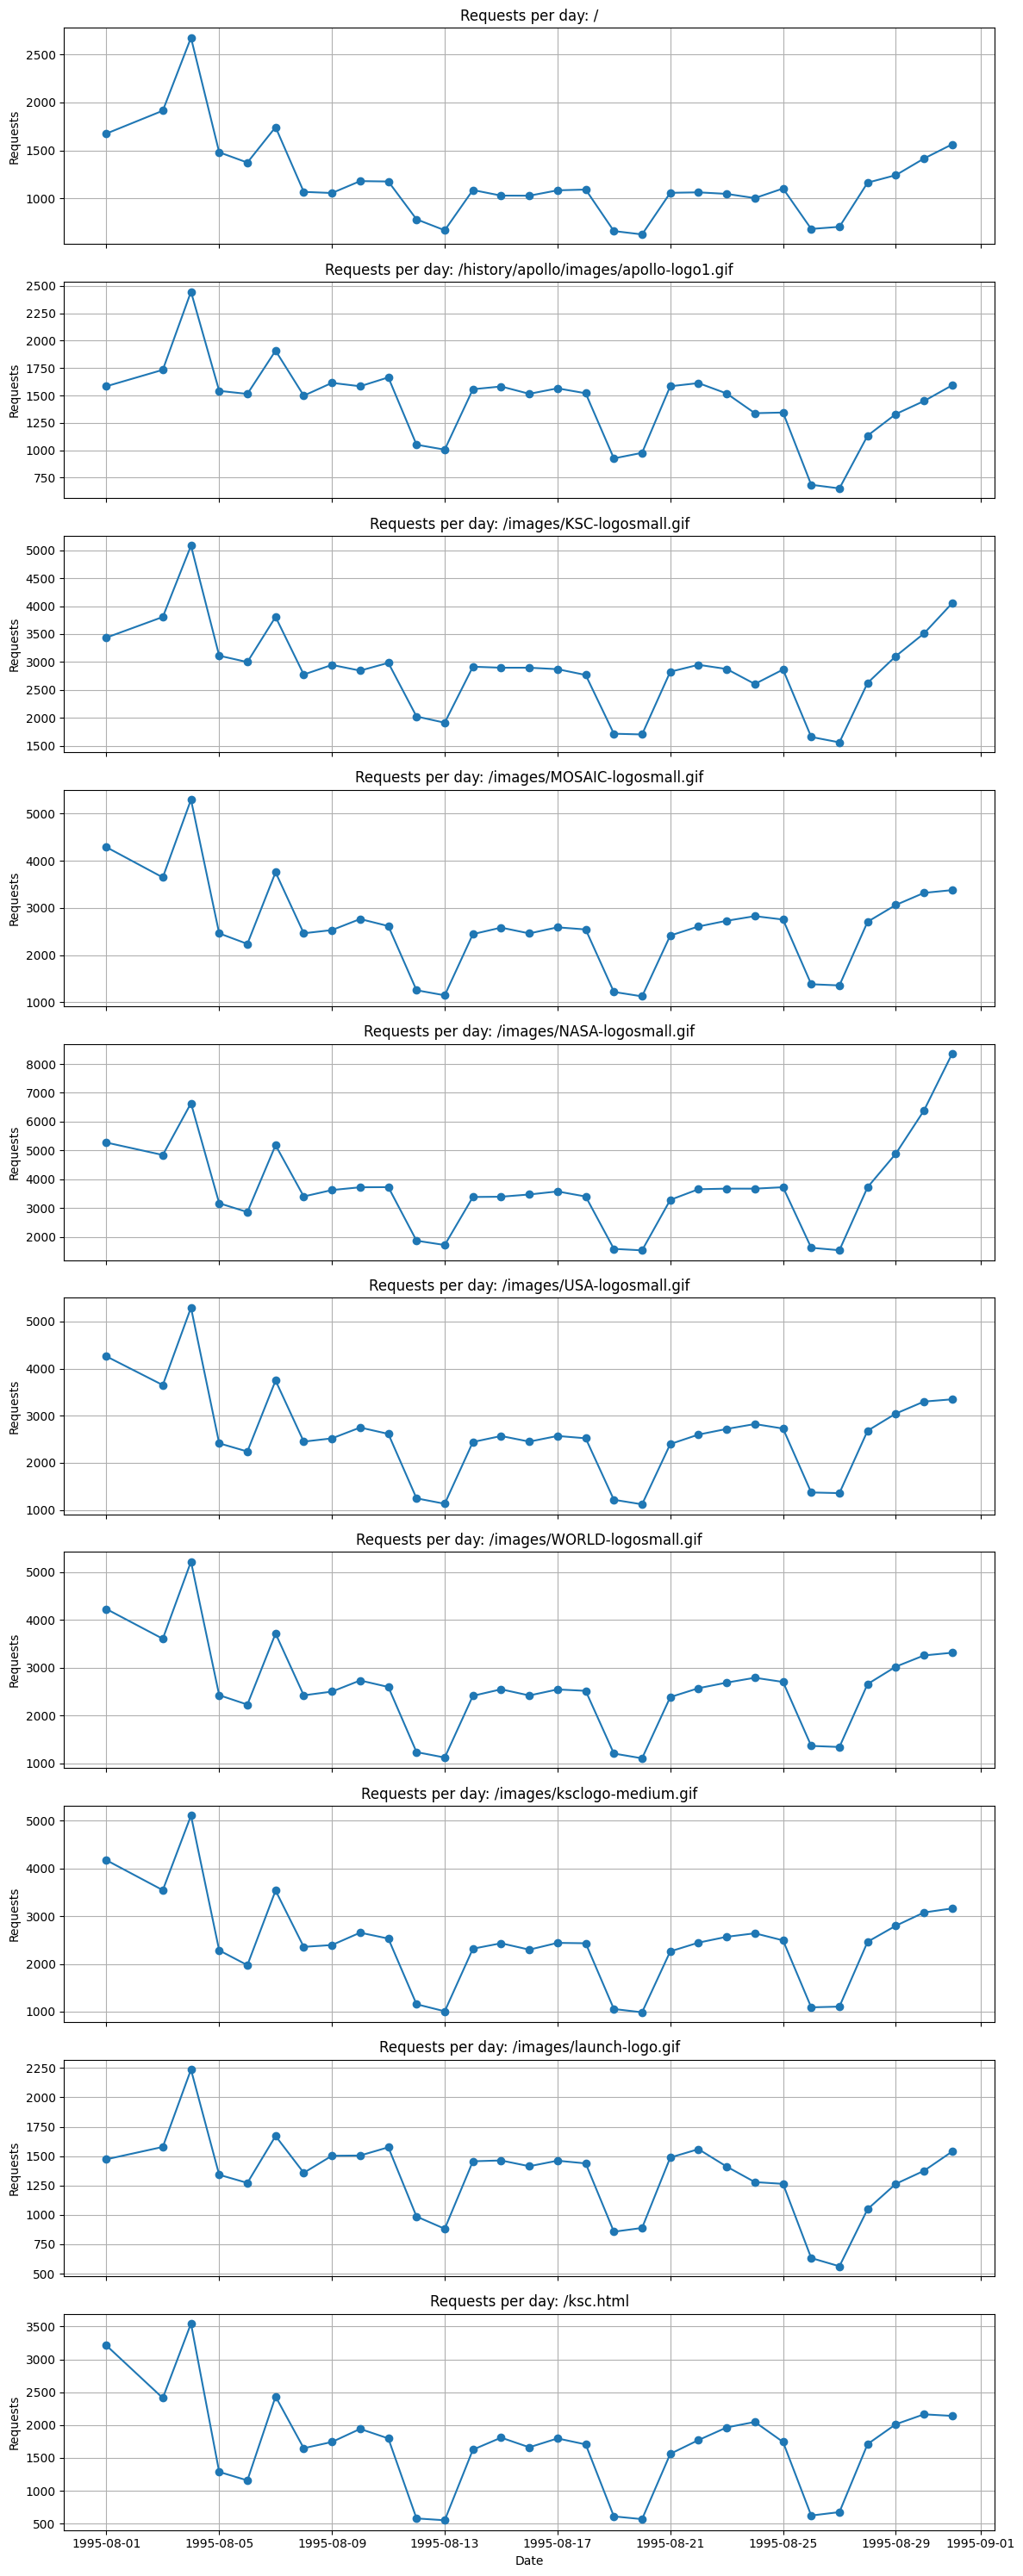

In [7]:
df_req = collect_requests_per_day(timeout_sec=20)
    
plot_requests_per_day(df_req)

[{'url': '/images/launch-logo.gif', 'total': 40529, 'success': 35821, 'failed': 4708}, {'url': '/', 'total': 36284, 'success': 32141, 'failed': 4143}, {'url': '/images/USA-logosmall.gif', 'total': 79738, 'success': 69942, 'failed': 9796}, {'url': '/images/WORLD-logosmall.gif', 'total': 79024, 'success': 69473, 'failed': 9551}, {'url': '/ksc.html', 'total': 52164, 'success': 49594, 'failed': 2570}, {'url': '/images/NASA-logosmall.gif', 'total': 113655, 'success': 92405, 'failed': 21250}, {'url': '/history/apollo/images/apollo-logo1.gif', 'total': 43834, 'success': 38912, 'failed': 4922}, {'url': '/images/MOSAIC-logosmall.gif', 'total': 80180, 'success': 70316, 'failed': 9864}, {'url': '/images/KSC-logosmall.gif', 'total': 87886, 'success': 74810, 'failed': 13076}, {'url': '/images/ksclogo-medium.gif', 'total': 74934, 'success': 66095, 'failed': 8839}]


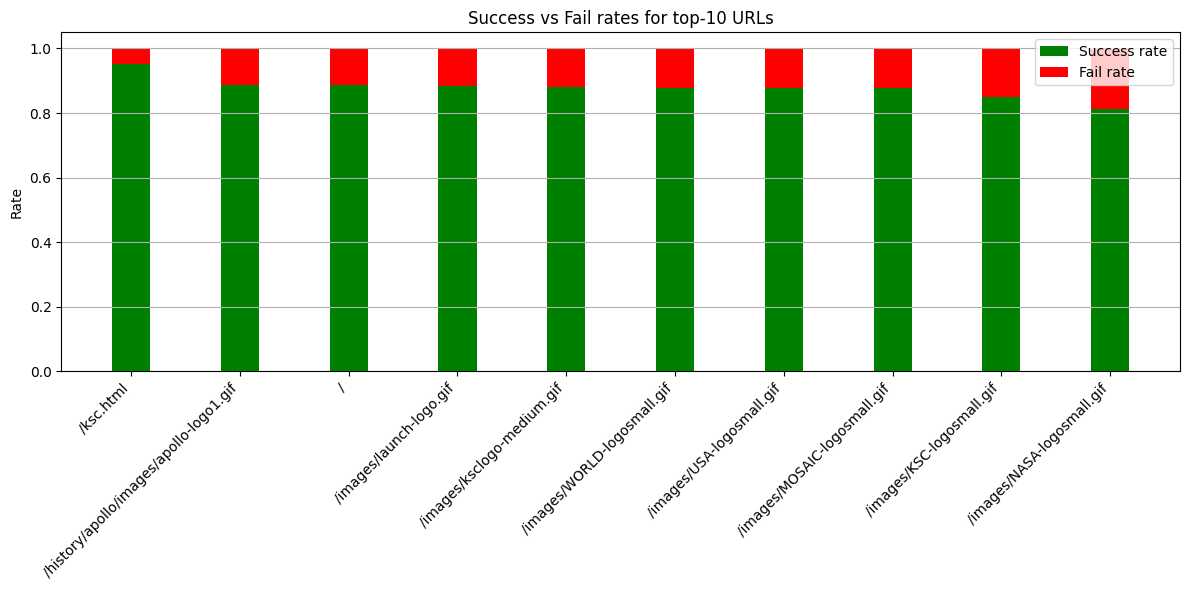

In [8]:
df_stat = collect_status_stats()

plot_success_fail_rates(df_stat)